In [8]:
import numpy as np
import matplotlib.pyplot as plt

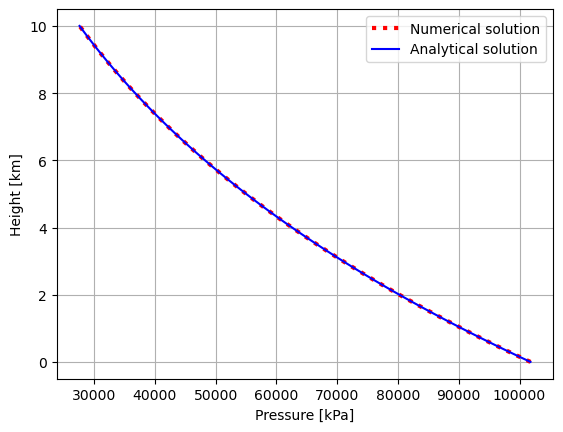

In [101]:
class atmosphere:

    def __init__(self, T_sfc=293, p_sfc=1.018*1e5, gamma=-6):
        self.T_sfc=T_sfc
        self.p_sfc=p_sfc
        self.gamma=gamma

    def p_z(self,z):
        # z must be array

        Rd=287.04
        g=9.81*1e3

        self.z=z
        Tz=self.T_sfc+self.gamma*(np.array(z))

        #numerical
        p=np.zeros(len(z))
        p[0]=self.p_sfc

        for i in range(len(Tz)-1):
            T=(Tz[i]+Tz[i+1])/2
            p[i+1]=p[i]*np.exp(-g*np.gradient(self.z)[0]/(Rd*T))

        #analytical
        self.pz_analytical=self.p_sfc*((self.T_sfc+self.gamma*self.z)/self.T_sfc)**(-g/(Rd*self.gamma))

        
        self.pz=p
        self.density=p/(Rd*T)

    def plot_pz(self):

        plt.plot(self.pz,self.z,label='Numerical solution',c='r',linewidth=3,linestyle='dotted')
        plt.plot(self.pz_analytical,self.z,label='Analytical solution',c='b')
        

        plt.xlabel("Pressure [kPa]")
        plt.ylabel("Height [km]")
        plt.grid()
        plt.legend()


model = atmosphere()
model.p_z(np.linspace(0,10,101))

model.plot_pz()

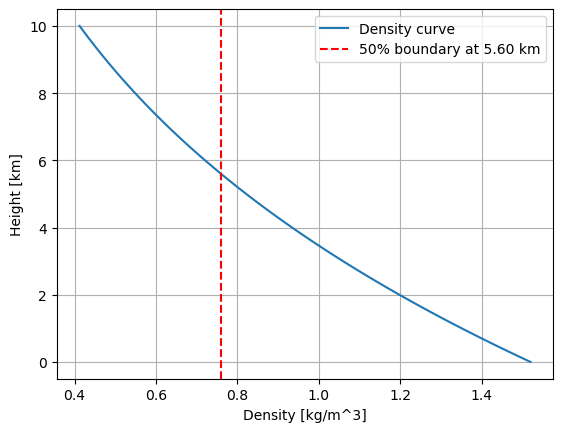

In [ ]:
plt.plot(model.density,model.z,label="Density curve")

boundary=0.5*model.density[0]
boundary_height=model.z[np.argmin(abs(boundary-model.density))]

plt.axvline(boundary,c='r',linestyle='--',label=f"50% boundary at {boundary_height:.2f} km")

plt.xlabel("Density [kg/m^3]")
plt.ylabel("Height [km]")
plt.grid()
plt.legend()

In [ ]:
RH=0.8
T_sfc=[271,303]
z=5